In [1]:
import pandas as pd
import yfinance as yf
from arch import arch_model
import matplotlib.pyplot as plt


## GARCH

Generalized AutoRegressive Conditional Heteroskedasticity

    A model that predicts how volatile an asset will be in future

Omega - Base volatility level (minimum vol)
Alpha - How much yesterday shock affect today volatility
Beta  - How much yesterday volatility carries over today    

In [2]:
sp500 = yf.download("SPY", period="5y")["Close"]["SPY"]
sp500_returns = sp500.pct_change(fill_method=None).dropna() * 100

[*********************100%***********************]  1 of 1 completed


In [3]:
model = arch_model(sp500_returns, vol="Garch", p=1, q=1)
model_fit = model.fit(disp="off")

print(model_fit.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                    SPY   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -1699.85
Distribution:                  Normal   AIC:                           3407.70
Method:            Maximum Likelihood   BIC:                           3428.24
                                        No. Observations:                 1255
Date:                Sun, Mar 15 2026   Df Residuals:                     1254
Time:                        00:00:38   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0809  2.337e-02      3.459  5.413e-04 [3.505e-0

Omega - Minimum vol = 0.0356 
Alpha = 0.1088  -> Today shock contribute 10.88% tomorrow vol 
Beta  =  0.8581 -> If yesterday is volatile - the  85.81% of yesterday volatile will exist today

Alpha + Beta = Volatility Persistence (How long does it takes the vol to vanish)
0.1088 +  0.8581 = 0.9669

close to 1 = longer it take to vanish
each day the factor shrink by the factor of (Alpha + Beta)

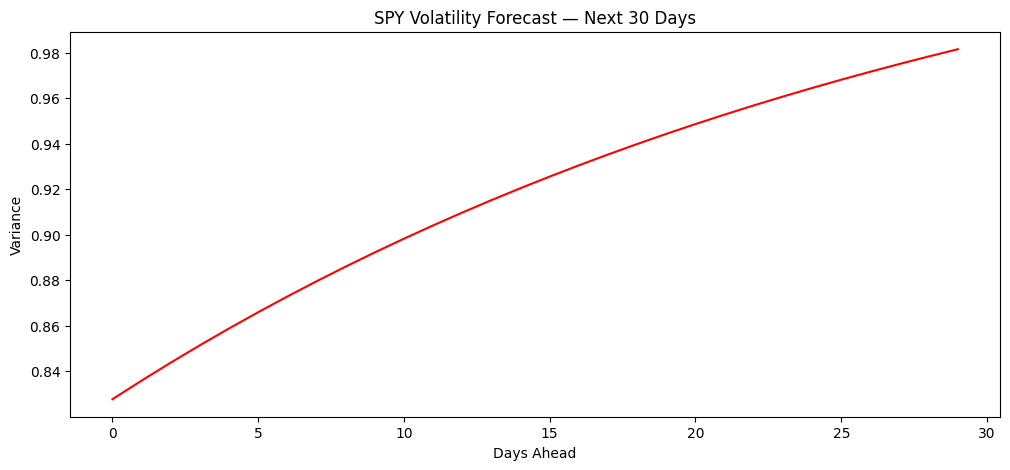

In [4]:
forecast = model_fit.forecast(horizon=30)
variance_forecast = forecast.variance.iloc[-1]

plt.figure(figsize=(12,5))
plt.plot(variance_forecast.values, color="red")
plt.title("SPY Volatility Forecast — Next 30 Days")
plt.xlabel("Days Ahead")
plt.ylabel("Variance")
plt.show()